# Hotel Reviews Analysis in Europe

## Programming for Data Science – Final Project

**Institution:** ESILV – École Supérieure d'Ingénieurs Léonard de Vinci

**Academic Year:** 2026–2027

**Professor:** Hugo Alatrista-Salas

**Team Members:**
- Youssef Damak
- Chaima Garoui
- Mariem Dridi
- Adam Nasri

**GitHub Repository:**
https://github.com/chaymaaaaa/hotel-reviews-analysis-Programming

---

## Individual Contribution

This notebook presents the following components:

- Data collection
- Exploratory Data Analysis (EDA)
- Data quality assessment
- Data preprocessing and transformation
- Query 1: Country-level grouping and aggregation
- Analytical visualizations
- Interpretation of results

The analysis follows the Knowledge Discovery in Databases
(KDD) methodology.

## 1. Introduction and Business Objectives

### 1.1 Business Context

Customer satisfaction plays an important role in the
hospitality industry. Online hotel reviews provide
valuable information about customer experiences,
service quality, preferences and expectations.

However, analyzing hundreds of thousands of reviews
manually is difficult and time-consuming. Data science
techniques can help transform these reviews into useful
information for decision-making.

### 1.2 Problem Statement

How can hotel review data be used to understand
customer satisfaction, identify recurring customer
preferences, predict temporal trends and discover
geographical patterns across European hotels?

### 1.3 Project Objectives

The project addresses four complementary analytical
queries:

- **Query 1 – Grouping and Aggregation:**
  Compare customer satisfaction, review volume and
  hotel representation across European countries.

- **Query 2 – Frequent Pattern Mining:**
  Identify recurring themes and patterns in positive
  and negative customer reviews.

- **Query 3 – Temporal Forecasting:**
  Analyze historical review activity and forecast
  future trends.

- **Query 4 – Spatial Clustering:**
  Identify geographical clusters of hotels using
  their spatial coordinates.

The analytical results will be presented through
visualizations and an interactive dashboard.

### 1.4 Scope of Individual Contribution

This notebook focuses on data collection, exploratory
data analysis, data preprocessing and Query 1.

The remaining analytical queries and dashboard will
be developed by the other team members and integrated
into the final collective notebook.

## 2. Dataset Description

### 2.1 Data Source

- **Dataset:** 515K Hotel Reviews Data in Europe
- **Platform:** Kaggle
- **Publisher:** Jiashen Liu
- **File:** Hotel_Reviews.csv
- **Source:** https://www.kaggle.com/datasets/jiashenliu/515k-hotel-reviews-data-in-europe

### 2.2 Dataset Characteristics

| Characteristic | Description |
|---|---|
| Number of observations | 515,738 |
| Number of original variables | 17 |
| Unit of observation | Individual hotel review |
| Distinct hotel names | 1,492 |
| Number of countries | 6 |
| First review date | August 4, 2015 |
| Last review date | August 3, 2017 |
| Data format | CSV |
| Data type | Numerical, categorical, textual, temporal and spatial |

The dataset covers six European countries: Austria,
France, Italy, the Netherlands, Spain and the
United Kingdom.

### 2.3 Variable Description

| Variable | Description |
|---|---|
| Hotel_Address | Geographical address of the hotel |
| Additional_Number_of_Scoring | Number of additional ratings without written reviews |
| Review_Date | Date of the customer review |
| Average_Score | Overall average rating of the hotel |
| Hotel_Name | Name of the hotel |
| Reviewer_Nationality | Nationality of the reviewer |
| Negative_Review | Negative feedback provided by the customer |
| Review_Total_Negative_Word_Counts | Number of words in the negative review |
| Total_Number_of_Reviews | Total number of reviews associated with the hotel |
| Positive_Review | Positive feedback provided by the customer |
| Review_Total_Positive_Word_Counts | Number of words in the positive review |
| Total_Number_of_Reviews_Reviewer_Has_Given | Number of reviews submitted by the reviewer |
| Reviewer_Score | Individual customer rating |
| Tags | Additional information about the customer's stay |
| days_since_review | Relative time elapsed since the review |
| lat | Hotel latitude |
| lng | Hotel longitude |

### 2.4 Analytical Dimensions

The dataset supports three complementary dimensions:

**Temporal dimension**

The Review_Date variable allows us to analyze the
evolution of review activity over time and develop
forecasting models.

**Spatial dimension**

Hotel_Address, lat and lng provide geographical
information that supports country-level analysis
and spatial clustering.

**Analytical dimension**

Reviewer_Score, Positive_Review and Negative_Review
allow us to analyze customer satisfaction and identify
recurring patterns in customer feedback.

### 2.5 Dataset Selection Justification

This dataset was selected because it combines a large
number of observations with multiple types of variables.

It allows the application of grouping, frequent pattern
mining, temporal forecasting and spatial clustering
within a single business context.

### 2.6 Data Availability and Reproducibility

The original dataset is not included in the GitHub
repository due to its large file size.

To reproduce the analysis, download the dataset from
the Kaggle source and place it in:

`data/raw/Hotel_Reviews.csv`

The preprocessing pipeline generates the cleaned
dataset automatically.

## 3. Methodology: Knowledge Discovery in Databases (KDD)

The project follows the Knowledge Discovery in Databases
(KDD) methodology to transform raw hotel review data
into meaningful analytical insights.

### 3.1 Data Selection

The hotel reviews dataset was selected from Kaggle
because it contains numerical, textual, temporal
and geographical information relevant to the
hospitality industry.

### 3.2 Data Preprocessing

An exploratory data analysis is performed to understand
the dataset structure and identify potential data
quality issues.

The preprocessing stage includes:

- Identification of missing values.
- Removal of exact duplicate records.
- Cleaning of textual variables.
- Verification of data quality.

Missing geographical coordinates are preserved at
this stage to avoid losing useful observations for
non-spatial analytical queries.

### 3.3 Data Transformation

The original dataset is transformed to facilitate
subsequent analytical tasks.

The transformations include:

- Conversion of Review_Date into datetime format.
- Extraction of the hotel country from Hotel_Address.
- Creation of a Hotel_ID using the hotel name and address.
- Preparation of a consistent cleaned dataset for
  all team members.

### 3.4 Data Mining

Four complementary analytical techniques are applied
or planned within the collective project:

- Grouping and aggregation for country-level analysis.
- Frequent pattern mining for customer review analysis.
- Time-series forecasting for temporal analysis.
- Spatial clustering for geographical analysis.

This individual contribution focuses on grouping
and aggregation through Query 1.

### 3.5 Interpretation and Evaluation

The analytical results are interpreted using
statistical indicators and appropriate visualizations.

The preprocessing and aggregation functions are
validated through 14 automated unit tests.

The complete individual pipeline is also executed
on the original dataset to verify reproducibility.

An interactive dashboard will be integrated into
the final collective project to facilitate exploration
and communication of the analytical results.

## 4. Python Environment and Configuration

The following libraries are used for data manipulation,
statistical analysis, visualization and file management.

Relative project paths are configured to ensure that
the notebook can run on different computers without
requiring changes to personal directory paths.

In [3]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from IPython.display import display, Image


# Identify the project root directory
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent


# Define portable project paths
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "Hotel_Reviews.csv"

PROCESSED_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "hotel_reviews_cleaned.csv"
)

RESULTS_PATH = PROJECT_ROOT / "results"


# Create output directories if necessary
PROCESSED_PATH.parent.mkdir(parents=True, exist_ok=True)
RESULTS_PATH.mkdir(parents=True, exist_ok=True)


# Configure visualization style
sns.set_theme(style="whitegrid")


# Verify project configuration
print("Project root:", PROJECT_ROOT)
print("Dataset path:", DATA_PATH)
print("Dataset exists:", DATA_PATH.exists())
print("Results directory:", RESULTS_PATH)
print("Libraries imported successfully.")

Project root: c:\Users\USER\Documents\hotel-reviews-analysis-Programming
Dataset path: c:\Users\USER\Documents\hotel-reviews-analysis-Programming\data\raw\Hotel_Reviews.csv
Dataset exists: True
Results directory: c:\Users\USER\Documents\hotel-reviews-analysis-Programming\results
Libraries imported successfully.


## 5. Data Collection

The first step of the analytical pipeline consists
of loading the original hotel reviews dataset.

The dataset is stored locally in CSV format.
The pandas library is used to load the data into
a DataFrame for subsequent exploration, preprocessing
and analytical processing.

A dedicated function is implemented to ensure
modularity and reproducibility.

In [4]:
# Function: load_data
# Input: Path to the original CSV dataset.
# Output: pandas DataFrame containing raw hotel reviews.

def load_data(file_path=DATA_PATH):
    """
    Purpose:
        Load the original hotel reviews dataset.

    Input:
        file_path: Path to the CSV dataset.

    Output:
        pandas DataFrame containing raw hotel reviews.
    """

    df = pd.read_csv(file_path)

    return df

In [5]:
# Load the original dataset
df = load_data()

# Verify successful data collection
print("Dataset loaded successfully.")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Display the first five observations
display(df.head())

Dataset loaded successfully.
Number of rows: 515738
Number of columns: 17


,Hotel_Address,Additional_Number_of_Scoring,Review_Date,Average_Score,Hotel_Name,Reviewer_Nationality,Negative_Review,Review_Total_Negative_Word_Counts,Total_Number_of_Reviews,Positive_Review,Review_Total_Positive_Word_Counts,Total_Number_of_Reviews_Reviewer_Has_Given,Reviewer_Score,Tags,days_since_review,lat,lng
0,s Gravesandestraat 55 Oost 1092 AA Amsterdam ...,194,8/3/2017,7.7,Hotel Arena,Russia,I am so angry that i made this post available...,397,1403,Only the park outside of the hotel was beauti...,11,7,2.9,"[' Leisure trip ', ' Couple ', ' Duplex Double...",0 days,52.360576,4.915968
1,s Gravesandestraat 55 Oost 1092 AA Amsterdam ...,194,8/3/2017,7.7,Hotel Arena,Ireland,No Negative,0,1403,No real complaints the hotel was great great ...,105,7,7.5,"[' Leisure trip ', ' Couple ', ' Duplex Double...",0 days,52.360576,4.915968
2,s Gravesandestraat 55 Oost 1092 AA Amsterdam ...,194,7/31/2017,7.7,Hotel Arena,Australia,Rooms are nice but for elderly a bit difficul...,42,1403,Location was good and staff were ok It is cut...,21,9,7.1,"[' Leisure trip ', ' Family with young childre...",3 days,52.360576,4.915968
3,s Gravesandestraat 55 Oost 1092 AA Amsterdam ...,194,7/31/2017,7.7,Hotel Arena,United Kingdom,My room was dirty and I was afraid to walk ba...,210,1403,Great location in nice surroundings the bar a...,26,1,3.8,"[' Leisure trip ', ' Solo traveler ', ' Duplex...",3 days,52.360576,4.915968
4,s Gravesandestraat 55 Oost 1092 AA Amsterdam ...,194,7/24/2017,7.7,Hotel Arena,New Zealand,You When I booked with your company on line y...,140,1403,Amazing location and building Romantic setting,8,3,6.7,"[' Leisure trip ', ' Couple ', ' Suite ', ' St...",10 days,52.360576,4.915968


### 6.2 Data Quality Assessment

Before performing data preprocessing, it is necessary
to evaluate the quality of the original dataset.

This assessment focuses on:

- Missing values and their percentages.
- Exact duplicate observations.
- Descriptive statistics of numerical variables.
- Minimum and maximum values.
- Distribution of customer satisfaction scores.

The results help justify the preprocessing decisions
and ensure the reliability of subsequent analyses.

In [6]:
# Function: analyze_data_quality
# Input: DataFrame containing raw hotel reviews.
# Output: None. Displays data quality indicators.

def analyze_data_quality(df):
    """
    Purpose:
        Evaluate the quality of the original dataset.

    Input:
        df: pandas DataFrame containing raw hotel reviews.

    Output:
        None. Displays missing values, duplicate counts
        and numerical descriptive statistics.
    """

    # Calculate missing values for each variable
    missing_values = df.isna().sum()

    # Calculate the percentage of missing values
    missing_percentage = (missing_values / len(df)) * 100

    # Create a data quality summary table
    missing_summary = pd.DataFrame({
        "Missing Values": missing_values,
        "Missing Percentage (%)": missing_percentage.round(2)
    })

    print("--- MISSING VALUES ---")
    display(missing_summary)

    # Identify exact duplicate observations
    duplicate_count = df.duplicated().sum()

    print("\n--- DUPLICATE ROWS ---")
    print("Number of duplicates:", duplicate_count)

    # Calculate descriptive statistics
    print("\n--- NUMERICAL DESCRIPTIVE STATISTICS ---")
    display(df.describe().T.round(2))

In [7]:
analyze_data_quality(df)

--- MISSING VALUES ---


,Missing Values,Missing Percentage (%)
Hotel_Address,0,0.00
Additional_Number_of_Scoring,0,0.00
Review_Date,0,0.00
Average_Score,0,0.00
Hotel_Name,0,0.00
Reviewer_Nationality,0,0.00
Negative_Review,0,0.00
Review_Total_Negative_Word_Counts,0,0.00
Total_Number_of_Reviews,0,0.00
Positive_Review,0,0.00



--- DUPLICATE ROWS ---
Number of duplicates: 526

--- NUMERICAL DESCRIPTIVE STATISTICS ---


,count,mean,std,min,25%,50%,75%,max
Additional_Number_of_Scoring,515738.0,498.08,500.54,1.00,169.00,341.00,660.00,2682.00
Average_Score,515738.0,8.40,0.55,5.20,8.10,8.40,8.80,9.80
Review_Total_Negative_Word_Counts,515738.0,18.54,29.69,0.00,2.00,9.00,23.00,408.00
Total_Number_of_Reviews,515738.0,2743.74,2317.46,43.00,1161.00,2134.00,3613.00,16670.00
Review_Total_Positive_Word_Counts,515738.0,17.78,21.80,0.00,5.00,11.00,22.00,395.00
Total_Number_of_Reviews_Reviewer_Has_Given,515738.0,7.17,11.04,1.00,1.00,3.00,8.00,355.00
Reviewer_Score,515738.0,8.40,1.64,2.50,7.50,8.80,9.60,10.00
lat,512470.0,49.44,3.47,41.33,48.21,51.50,51.52,52.40
lng,512470.0,2.82,4.58,-0.37,-0.14,0.01,4.83,16.43


### Interpretation of Data Quality

The data quality assessment identified 526 exact
duplicate observations, representing approximately
0.10% of the original dataset.

These observations will be removed during preprocessing
to avoid counting identical records multiple times.

Missing values are found exclusively in the latitude
and longitude variables. Each variable contains
3,268 missing values, representing approximately
0.63% of the dataset.

These observations will be preserved because they
remain useful for aggregation, text mining and
temporal analysis.

Missing coordinates will be handled separately
during spatial clustering.

The average customer review score is 8.40 out of 10,
with a median of 8.80 and a standard deviation of 1.64.

Individual reviewer scores range from 2.50 to 10.00,
indicating generally high customer satisfaction
among the observed reviews.

### 6.3 Temporal and Spatial Exploration

This section explores the temporal and geographical
characteristics of the original hotel reviews dataset.

The temporal analysis identifies:

- The first and last review dates.
- The number of months covered by the dataset.
- Potential invalid review dates.

The spatial analysis identifies:

- The number of distinct hotel names.
- The countries represented in the dataset.
- The distribution of reviews across countries.
- Potential unidentified geographical locations.

These indicators provide a foundation for temporal
forecasting, geographical aggregation and spatial
clustering.

In [8]:
# Function: explore_temporal_spatial
# Input: DataFrame containing raw hotel reviews.
# Output: None. Displays temporal and spatial indicators.

def explore_temporal_spatial(df):
    """
    Purpose:
        Explore the temporal and geographical coverage
        of the original hotel reviews dataset.

    Input:
        df: pandas DataFrame containing raw hotel reviews.

    Output:
        None. Displays temporal coverage, distinct hotel
        names and geographical distribution.
    """

    # Convert dates temporarily without modifying raw data
    dates = pd.to_datetime(
        df["Review_Date"],
        format="%m/%d/%Y",
        errors="coerce"
    )

    # Analyze temporal coverage
    print("--- TEMPORAL COVERAGE ---")
    print("First review date:", dates.min())
    print("Last review date:", dates.max())
    print("Invalid dates:", dates.isna().sum())
    print("Number of months:", dates.dt.to_period("M").nunique())

    # Count distinct hotel names
    print("\n--- HOTEL INFORMATION ---")
    print("Distinct hotel names:", df["Hotel_Name"].nunique())

    # Extract countries from hotel addresses
    countries = df["Hotel_Address"].str.strip().str.extract(
        r"(United Kingdom|Netherlands|France|Spain|Italy|Austria)$",
        expand=False
    )

    # Analyze geographical coverage
    print("\n--- GEOGRAPHICAL COVERAGE ---")
    print("Number of countries:", countries.nunique())

    # Display the number of reviews per country
    print("\nNumber of reviews per country:")

    display(
        countries.value_counts().to_frame(
            name="Number of Reviews"
        )
    )

    # Identify addresses without a recognized country
    print("\nUnidentified countries:", countries.isna().sum())

In [9]:
explore_temporal_spatial(df)

--- TEMPORAL COVERAGE ---
First review date: 2015-08-04 00:00:00
Last review date: 2017-08-03 00:00:00
Invalid dates: 0
Number of months: 25

--- HOTEL INFORMATION ---
Distinct hotel names: 1492

--- GEOGRAPHICAL COVERAGE ---
Number of countries: 6

Number of reviews per country:


,Number of Reviews
Hotel_Address,
United Kingdom,262301
Spain,60149
France,59928
Netherlands,57214
Austria,38939
Italy,37207



Unidentified countries: 0


### Interpretation of Temporal and Spatial Exploration

The dataset covers the period from August 4, 2015,
to August 3, 2017, representing 25 calendar months.

No invalid review dates were identified.

However, the first and last months are incomplete.
This limitation must be considered when performing
monthly time-series forecasting.

The dataset contains 1,492 distinct hotel names
distributed across six European countries.

The United Kingdom has the highest number of reviews,
representing approximately 50.86% of the original dataset.

This geographical imbalance should be considered
when comparing customer satisfaction across countries.

All hotel addresses were successfully associated
with one of the six countries.

The number of distinct hotel names does not necessarily
represent the exact number of physical hotels because
different hotels may share the same name.

A hotel identifier combining the hotel name and address
will therefore be created during preprocessing.

### 6.4 Exploratory Data Visualizations

Three visualizations are generated to better understand
the characteristics of the original dataset:

1. Distribution of individual reviewer scores.
2. Number of reviews per country.
3. Evolution of monthly review activity.

These visualizations complement the descriptive
statistics and help identify patterns, geographical
imbalances and temporal trends.

In [10]:
# Function: plot_eda
# Input: DataFrame containing raw hotel reviews.
# Output: None. Displays and saves three EDA charts.

def plot_eda(df):
    """
    Purpose:
        Visualize the main characteristics of the
        original hotel reviews dataset.

    Input:
        df: pandas DataFrame containing raw hotel reviews.

    Output:
        None. Displays three charts and saves them
        as PNG files in the results directory.
    """

    RESULTS_PATH.mkdir(parents=True, exist_ok=True)

    sns.set_theme(style="whitegrid")

    # 1. Distribution of reviewer scores
    # A histogram helps identify the distribution
    # and concentration of customer ratings.

    plt.figure(figsize=(10, 6))

    sns.histplot(
        data=df,
        x="Reviewer_Score",
        bins=30,
        kde=True,
        color="steelblue"
    )

    plt.title("Distribution of Reviewer Scores")
    plt.xlabel("Reviewer Score")
    plt.ylabel("Frequency")
    plt.tight_layout()

    plt.savefig(
        RESULTS_PATH / "reviewer_score_distribution.png",
        dpi=300
    )

    plt.show()
    plt.close()

    # 2. Number of reviews per country
    # Extract countries without modifying the raw data.

    countries = df["Hotel_Address"].str.strip().str.extract(
        r"(United Kingdom|Netherlands|France|Spain|Italy|Austria)$",
        expand=False
    )

    country_counts = countries.value_counts()

    plt.figure(figsize=(10, 6))

    sns.barplot(
        x=country_counts.index,
        y=country_counts.values,
        color="steelblue"
    )

    plt.title("Number of Reviews per Country")
    plt.xlabel("Country")
    plt.ylabel("Number of Reviews")
    plt.xticks(rotation=30)
    plt.tight_layout()

    plt.savefig(
        RESULTS_PATH / "reviews_per_country.png",
        dpi=300
    )

    plt.show()
    plt.close()

    # 3. Monthly review trends
    # Aggregate individual reviews by calendar month.

    dates = pd.to_datetime(
        df["Review_Date"],
        format="%m/%d/%Y",
        errors="coerce"
    )

    monthly_counts = (
        dates.dt.to_period("M")
        .value_counts()
        .sort_index()
    )

    monthly_counts.index = monthly_counts.index.to_timestamp()

    plt.figure(figsize=(12, 6))

    plt.plot(
        monthly_counts.index,
        monthly_counts.values,
        marker="o",
        color="steelblue"
    )

    plt.title("Monthly Hotel Review Trends")
    plt.xlabel("Date")
    plt.ylabel("Number of Reviews")
    plt.xticks(rotation=45)
    plt.tight_layout()

    plt.savefig(
        RESULTS_PATH / "monthly_review_trends.png",
        dpi=300
    )

    plt.show()
    plt.close()

    print("\n--- EDA VISUALIZATIONS ---")
    print("Three visualizations saved in results/")

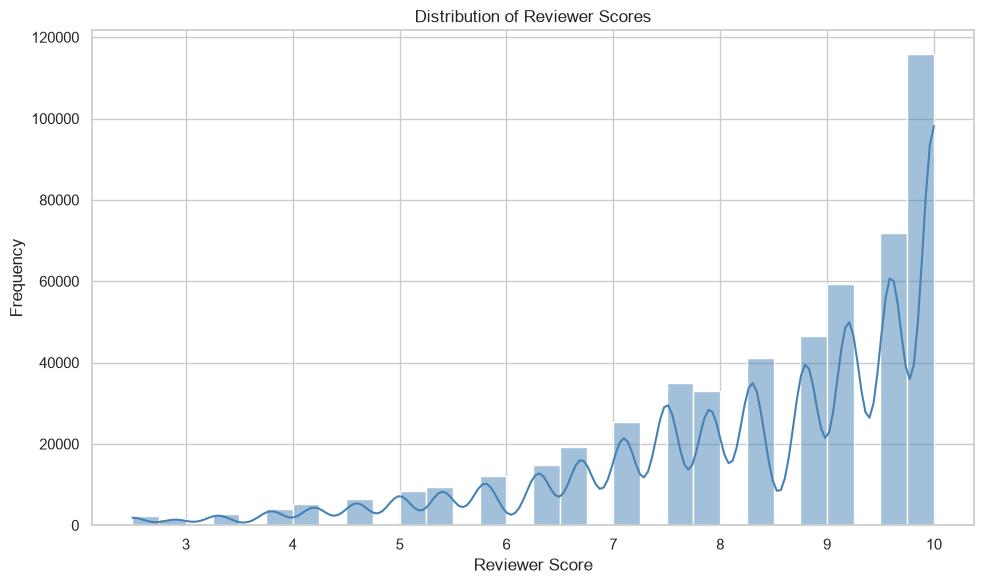

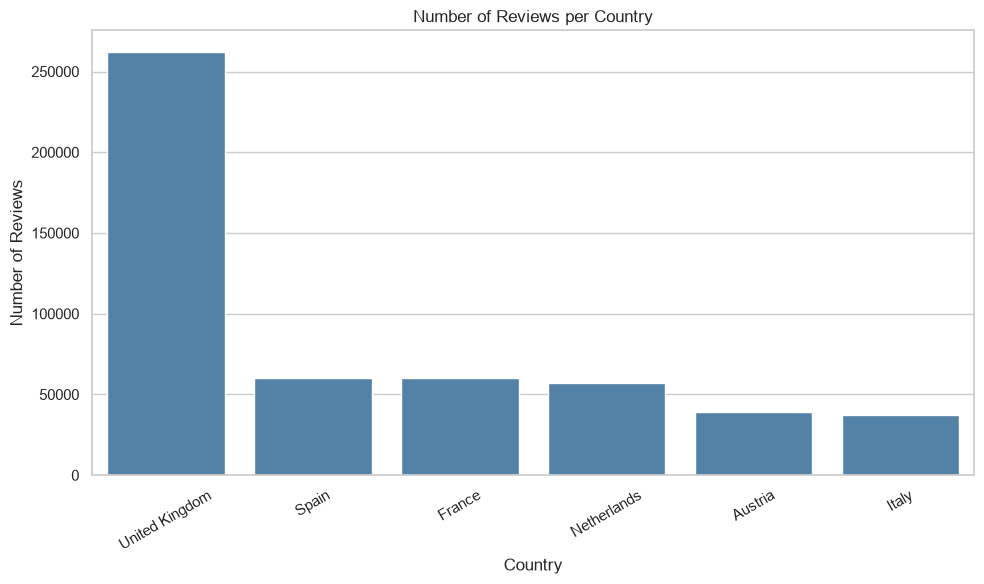

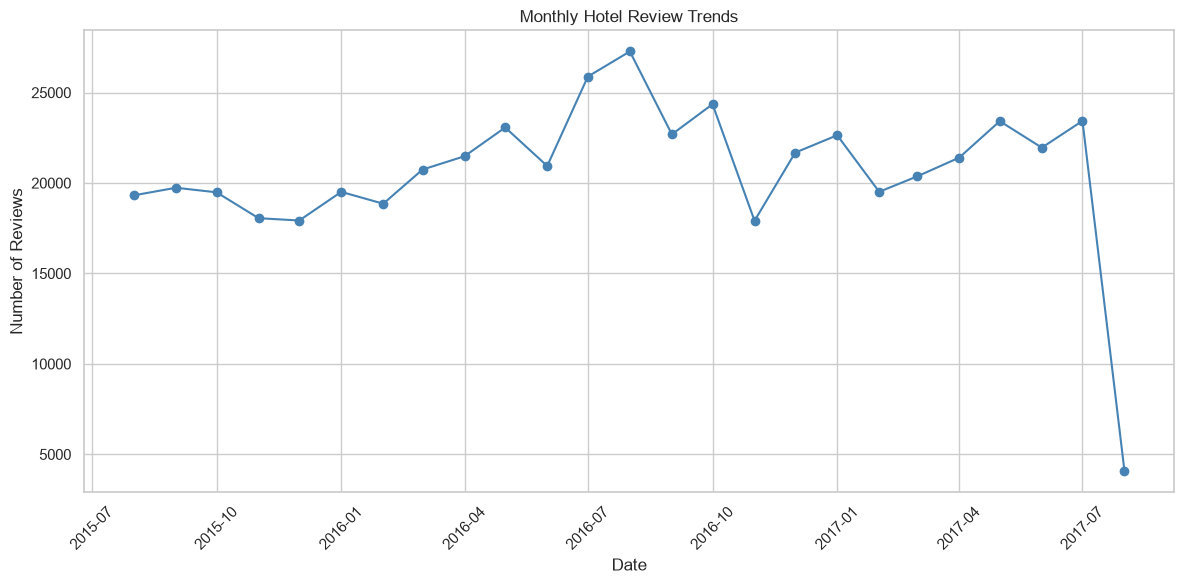


--- EDA VISUALIZATIONS ---
Three visualizations saved in results/


In [11]:
plot_eda(df)

### Interpretation of Exploratory Visualizations

#### Visualization 1: Distribution of Reviewer Scores

The distribution of reviewer scores is negatively
skewed, with most observations concentrated toward
higher ratings.

The average reviewer score is 8.40, while the
median is 8.80.

This suggests generally high customer satisfaction
among the reviews represented in the dataset.

#### Visualization 2: Number of Reviews per Country

The United Kingdom has the largest number of reviews,
representing approximately 50.86% of the dataset.

The remaining five countries have considerably
fewer observations.

This geographical imbalance should be considered
when interpreting country-level comparisons.

#### Visualization 3: Monthly Hotel Review Trends

The monthly review counts fluctuate throughout
the observation period.

The number of reviews reaches a peak around
August 2016.

The first and last months are incomplete because
the dataset begins on August 4, 2015, and ends
on August 3, 2017.

The low review count in August 2017 should therefore
not be interpreted as a significant decline in
customer activity.

This limitation is particularly important for
subsequent temporal forecasting.

## 7. Data Preprocessing and Transformation

Based on the exploratory data analysis, several
preprocessing operations are performed to improve
data quality and prepare the dataset for the four
analytical queries.

### 7.1 Preprocessing Strategy

| Operation | Justification |
|---|---|
| Remove exact duplicates | Avoid counting identical observations multiple times |
| Convert review dates | Enable temporal analysis and forecasting |
| Remove unnecessary spaces | Improve consistency of textual variables |
| Extract hotel countries | Enable country-level grouping |
| Create hotel identifiers | Distinguish hotels using their names and addresses |
| Preserve missing coordinates | Avoid losing useful observations for non-spatial analysis |

The original dataset is preserved, and all
transformations are applied to a copy.

Missing geographical coordinates will be handled
separately during spatial clustering.

In [12]:
# Function: clean_data
# Input: DataFrame containing raw hotel reviews.
# Output: DataFrame containing cleaned hotel reviews.

def clean_data(df):
    """
    Purpose:
        Clean and transform the original dataset
        to prepare it for subsequent analytical queries.

    Input:
        df: pandas DataFrame containing raw hotel reviews.

    Output:
        pandas DataFrame containing cleaned and
        transformed hotel reviews.
    """

    # Preserve the original dataset
    df = df.copy()

    initial_rows = len(df)

    # 1. Remove exact duplicate observations
    df = df.drop_duplicates().reset_index(drop=True)

    # 2. Convert review dates to datetime format
    df["Review_Date"] = pd.to_datetime(
        df["Review_Date"],
        format="%m/%d/%Y",
        errors="coerce"
    )

    # 3. Clean textual variables
    text_columns = [
        "Hotel_Name",
        "Hotel_Address",
        "Reviewer_Nationality",
        "Positive_Review",
        "Negative_Review"
    ]

    for column in text_columns:
        df[column] = df[column].str.strip()

    # 4. Extract hotel countries from addresses
    df["Country"] = df["Hotel_Address"].str.extract(
        r"(United Kingdom|Netherlands|France|Spain|Italy|Austria)$",
        expand=False
    )

    # 5. Create a hotel identifier
    # Combining name and address helps distinguish
    # hotels that may share the same name.
    df["Hotel_ID"] = (
        df["Hotel_Name"] + " | " + df["Hotel_Address"]
    )

    # 6. Preserve missing geographical coordinates
    # These will be handled during spatial clustering.

    # Display preprocessing results
    print("--- DATA PREPROCESSING ---")
    print("Initial rows:", initial_rows)
    print("Removed duplicates:", initial_rows - len(df))
    print("Remaining rows:", len(df))
    print("Number of columns:", df.shape[1])
    print("Invalid dates:", df["Review_Date"].isna().sum())
    print("Missing countries:", df["Country"].isna().sum())
    print("Distinct hotel identifiers:", df["Hotel_ID"].nunique())
    print("Missing latitude:", df["lat"].isna().sum())
    print("Missing longitude:", df["lng"].isna().sum())

    return df

In [13]:
# Function: save_cleaned_data
# Input: Cleaned DataFrame and destination file path.
# Output: None. Saves the cleaned dataset as a CSV file.

def save_cleaned_data(df, file_path=PROCESSED_PATH):
    """
    Purpose:
        Export the cleaned dataset for reproducibility
        and subsequent analytical queries.

    Input:
        df: pandas DataFrame containing cleaned reviews.
        file_path: Destination CSV path.

    Output:
        None. Saves the cleaned dataset locally.
    """

    file_path = Path(file_path)

    # Create the destination directory if necessary
    file_path.parent.mkdir(parents=True, exist_ok=True)

    # Export without the pandas index
    df.to_csv(file_path, index=False)

    print("\n--- CLEANED DATASET SAVED ---")
    print("Location:", file_path)

In [14]:
# Execute the preprocessing pipeline
cleaned_df = clean_data(df)

# Save the cleaned dataset
save_cleaned_data(cleaned_df)

# Display the first five cleaned observations
display(cleaned_df.head())

--- DATA PREPROCESSING ---
Initial rows: 515738
Removed duplicates: 526
Remaining rows: 515212
Number of columns: 19
Invalid dates: 0
Missing countries: 0
Distinct hotel identifiers: 1494
Missing latitude: 3268
Missing longitude: 3268

--- CLEANED DATASET SAVED ---
Location: c:\Users\USER\Documents\hotel-reviews-analysis-Programming\data\processed\hotel_reviews_cleaned.csv


,Hotel_Address,Additional_Number_of_Scoring,Review_Date,Average_Score,Hotel_Name,Reviewer_Nationality,Negative_Review,Review_Total_Negative_Word_Counts,Total_Number_of_Reviews,Positive_Review,Review_Total_Positive_Word_Counts,Total_Number_of_Reviews_Reviewer_Has_Given,Reviewer_Score,Tags,days_since_review,lat,lng,Country,Hotel_ID
0,s Gravesandestraat 55 Oost 1092 AA Amsterdam N...,194,2017-08-03,7.7,Hotel Arena,Russia,I am so angry that i made this post available ...,397,1403,Only the park outside of the hotel was beautiful,11,7,2.9,"[' Leisure trip ', ' Couple ', ' Duplex Double...",0 days,52.360576,4.915968,Netherlands,Hotel Arena | s Gravesandestraat 55 Oost 1092 ...
1,s Gravesandestraat 55 Oost 1092 AA Amsterdam N...,194,2017-08-03,7.7,Hotel Arena,Ireland,No Negative,0,1403,No real complaints the hotel was great great l...,105,7,7.5,"[' Leisure trip ', ' Couple ', ' Duplex Double...",0 days,52.360576,4.915968,Netherlands,Hotel Arena | s Gravesandestraat 55 Oost 1092 ...
2,s Gravesandestraat 55 Oost 1092 AA Amsterdam N...,194,2017-07-31,7.7,Hotel Arena,Australia,Rooms are nice but for elderly a bit difficult...,42,1403,Location was good and staff were ok It is cute...,21,9,7.1,"[' Leisure trip ', ' Family with young childre...",3 days,52.360576,4.915968,Netherlands,Hotel Arena | s Gravesandestraat 55 Oost 1092 ...
3,s Gravesandestraat 55 Oost 1092 AA Amsterdam N...,194,2017-07-31,7.7,Hotel Arena,United Kingdom,My room was dirty and I was afraid to walk bar...,210,1403,Great location in nice surroundings the bar an...,26,1,3.8,"[' Leisure trip ', ' Solo traveler ', ' Duplex...",3 days,52.360576,4.915968,Netherlands,Hotel Arena | s Gravesandestraat 55 Oost 1092 ...
4,s Gravesandestraat 55 Oost 1092 AA Amsterdam N...,194,2017-07-24,7.7,Hotel Arena,New Zealand,You When I booked with your company on line yo...,140,1403,Amazing location and building Romantic setting,8,3,6.7,"[' Leisure trip ', ' Couple ', ' Suite ', ' St...",10 days,52.360576,4.915968,Netherlands,Hotel Arena | s Gravesandestraat 55 Oost 1092 ...


### 7.2 Interpretation of Preprocessing Results

After removing 526 exact duplicate observations,
the cleaned dataset contains 515,212 review records.

Two new variables were created:

- Country: identifies the country where the hotel
  is located.
- Hotel_ID: combines the hotel name and address
  to distinguish hotel records.

Consequently, the number of variables increased
from 17 to 19.

All review dates were successfully converted into
datetime format, and all countries were identified.

The cleaned dataset contains 1,494 distinct
hotel identifiers.

Missing geographical coordinates were intentionally
preserved to avoid unnecessary information loss.

The cleaned dataset is exported locally and provides
a common data foundation for all four analytical
queries.

### 7.3 Preprocessing Limitations

Exact duplicate records are assumed to represent
redundant observations.

The constructed Hotel_ID is not an official hotel
identifier and may be affected by variations in
hotel names or addresses.

Missing geographical coordinates require additional
handling during spatial clustering.

When the cleaned CSV file is loaded again, the
Review_Date variable must be converted back into
datetime format if required for temporal analysis.

## 8. Query 1 – Country-Level Grouping and Aggregation

### 8.1 Research Question

How does customer satisfaction vary across European
countries, and how does it relate to the number of
hotels and customer reviews?

### 8.2 Business Objective

The objective is to compare customer satisfaction
and review activity across the six European countries
represented in the dataset.

This analysis can help hospitality businesses
understand geographical differences in customer
feedback and identify potential areas for improvement.

### 8.3 Analytical Technique

Grouping and aggregation are performed using the
pandas groupby() and agg() methods.

The cleaned dataset is grouped according to the
Country variable.

### 8.4 Definition of Analytical Indicators

| Indicator | Definition | Calculation |
|---|---|---|
| Number of Reviews | Total number of review records per country | size() |
| Number of Hotels | Number of distinct hotel identifiers per country | nunique() |
| Average Reviewer Score | Arithmetic mean of individual customer ratings | mean() |
| Median Reviewer Score | Central value of individual customer ratings | median() |

The average score measures overall customer
satisfaction, while the median provides an indicator
that is less sensitive to extreme ratings.

The review count measures customer review activity,
while the hotel count describes geographical
representation within the dataset.

In [15]:
# Function: aggregate_by_country
# Input: DataFrame containing cleaned hotel reviews.
# Output: DataFrame containing country-level indicators.

def aggregate_by_country(df):
    """
    Purpose:
        Compare customer satisfaction and review
        activity across European countries.

    Input:
        df: pandas DataFrame containing cleaned reviews,
        including Country, Hotel_ID and Reviewer_Score.

    Output:
        pandas DataFrame containing review counts,
        distinct hotel identifiers, average scores
        and median scores for each country.
    """

    # Group observations by country and calculate
    # the four analytical indicators.
    country_summary = (
        df.groupby("Country")
        .agg(
            Number_of_Reviews=("Reviewer_Score", "size"),
            Number_of_Hotels=("Hotel_ID", "nunique"),
            Average_Reviewer_Score=("Reviewer_Score", "mean"),
            Median_Reviewer_Score=("Reviewer_Score", "median")
        )
        .reset_index()
    )

    # Sort countries by average customer satisfaction.
    country_summary = country_summary.sort_values(
        by="Average_Reviewer_Score",
        ascending=False
    ).reset_index(drop=True)

    # Round numerical results for readability.
    country_summary = country_summary.round(2)

    print("--- QUERY 1: COUNTRY AGGREGATION ---")

    display(country_summary)

    return country_summary

In [16]:
# Function: save_aggregation_results
# Input: DataFrame containing country-level indicators.
# Output: None. Exports analytical results as CSV.

def save_aggregation_results(country_summary):
    """
    Purpose:
        Export Query 1 results for reproducibility
        and future dashboard integration.

    Input:
        country_summary: pandas DataFrame containing
        country-level analytical indicators.

    Output:
        None. Saves country_summary.csv in results/.
    """

    # Create the results directory if necessary.
    RESULTS_PATH.mkdir(parents=True, exist_ok=True)

    # Define the output file.
    output_path = RESULTS_PATH / "country_summary.csv"

    # Export results without the pandas index.
    country_summary.to_csv(output_path, index=False)

    print("\n--- QUERY 1 RESULTS SAVED ---")
    print("Location:", output_path)

In [17]:
# Calculate country-level analytical indicators
country_summary = aggregate_by_country(cleaned_df)

# Export Query 1 results
save_aggregation_results(country_summary)

--- QUERY 1: COUNTRY AGGREGATION ---


,Country,Number_of_Reviews,Number_of_Hotels,Average_Reviewer_Score,Median_Reviewer_Score
0,Spain,60149,211,8.55,9.2
1,Austria,38937,158,8.55,8.8
2,Netherlands,57211,105,8.46,8.8
3,France,59413,458,8.42,8.8
4,Italy,37204,162,8.35,8.8
5,United Kingdom,262298,400,8.32,8.8



--- QUERY 1 RESULTS SAVED ---
Location: c:\Users\USER\Documents\hotel-reviews-analysis-Programming\results\country_summary.csv


In [18]:
# Verify the consistency of Query 1 results
assert len(country_summary) == 6

assert country_summary["Number_of_Reviews"].sum() == len(cleaned_df)

assert country_summary["Number_of_Hotels"].sum() == (
    cleaned_df["Hotel_ID"].nunique()
)

assert country_summary["Average_Reviewer_Score"].between(0, 10).all()

print("All Query 1 validation checks passed.")

All Query 1 validation checks passed.


### 8.5 Interpretation of Aggregation Results

Spain and Austria have the highest average reviewer
scores after rounding, with a displayed score of 8.55.

The United Kingdom has the lowest average reviewer
score of 8.32, despite having the largest number
of reviews.

France has the largest number of distinct hotel
identifiers, with 458 represented in the dataset.

Spain also has the highest median reviewer score,
at 9.20, compared with 8.80 for the other countries.

The difference between the highest and lowest
displayed average scores is only 0.23 points.

These results indicate that customer satisfaction
is generally high across all six countries.

### 8.6 Analytical Limitations

The average reviewer score is calculated at the
individual review level rather than the hotel level.

Consequently, hotels with more reviews contribute
more to the country-level average.

The dataset is geographically imbalanced, with
the United Kingdom accounting for approximately
half of all review records.

The number of hotels represents distinct constructed
hotel identifiers within the dataset, not the total
number of hotels operating in each country.

The analysis is descriptive and does not establish
causal relationships between geographical location,
review volume and customer satisfaction.S

### 8.7 Visualization of Query 1 Results

Three analytical visualizations are generated to
facilitate the interpretation of country-level
aggregation results:

1. Average customer satisfaction by country.
2. Number of hotels represented in each country.
3. Relationship between review volume and
   average customer satisfaction.

Bar charts are used to compare indicators across
geographical categories, while a scatter plot
is used to explore the relationship between
two numerical indicators.

In [19]:
# Function: plot_country_summary
# Input: DataFrame containing country-level indicators.
# Output: None. Displays and saves three analytical charts.

def plot_country_summary(country_summary):
    """
    Purpose:
        Visualize Query 1 results and compare customer
        satisfaction, hotel representation and review
        activity across European countries.

    Input:
        country_summary: pandas DataFrame containing
        country-level aggregation results.

    Output:
        None. Displays and saves three analytical charts.
    """

    RESULTS_PATH.mkdir(parents=True, exist_ok=True)

    sns.set_theme(style="whitegrid")

    # 1. Average reviewer score by country
    # A bar chart facilitates comparison of customer
    # satisfaction across geographical categories.

    plt.figure(figsize=(10, 6))

    ax = sns.barplot(
        data=country_summary,
        x="Country",
        y="Average_Reviewer_Score",
        color="steelblue"
    )

    ax.bar_label(ax.containers[0], fmt="%.2f")

    plt.title("Average Customer Satisfaction by Country")
    plt.xlabel("Country")
    plt.ylabel("Average Reviewer Score")

    # Use the full rating scale to avoid exaggerating
    # differences between countries.
    plt.ylim(0, 10)

    plt.xticks(rotation=30)
    plt.tight_layout()

    plt.savefig(
        RESULTS_PATH / "q1_average_score_by_country.png",
        dpi=300
    )

    plt.show()
    plt.close()

    # 2. Number of hotels by country
    # Sort countries by the number of hotel identifiers.

    hotel_summary = country_summary.sort_values(
        "Number_of_Hotels",
        ascending=False
    )

    plt.figure(figsize=(10, 6))

    ax = sns.barplot(
        data=hotel_summary,
        x="Country",
        y="Number_of_Hotels",
        color="steelblue"
    )

    ax.bar_label(ax.containers[0], fmt="%d")

    plt.title("Number of Hotels per Country")
    plt.xlabel("Country")
    plt.ylabel("Number of Hotels")
    plt.xticks(rotation=30)
    plt.tight_layout()

    plt.savefig(
        RESULTS_PATH / "q1_hotels_by_country.png",
        dpi=300
    )

    plt.show()
    plt.close()

    # 3. Review volume versus customer satisfaction
    # Each point represents one country.
    # The scatter plot explores the relationship
    # between two numerical indicators.

    plt.figure(figsize=(11, 6))

    sns.scatterplot(
        data=country_summary,
        x="Number_of_Reviews",
        y="Average_Reviewer_Score",
        hue="Country",
        s=150
    )

    plt.title("Review Volume vs Customer Satisfaction")
    plt.xlabel("Number of Reviews")
    plt.ylabel("Average Reviewer Score")
    plt.legend(title="Country")
    plt.tight_layout()

    plt.savefig(
        RESULTS_PATH / "q1_reviews_vs_satisfaction.png",
        dpi=300
    )

    plt.show()
    plt.close()

    print("\n--- QUERY 1 VISUALIZATIONS ---")
    print("Three aggregation charts saved in results/")

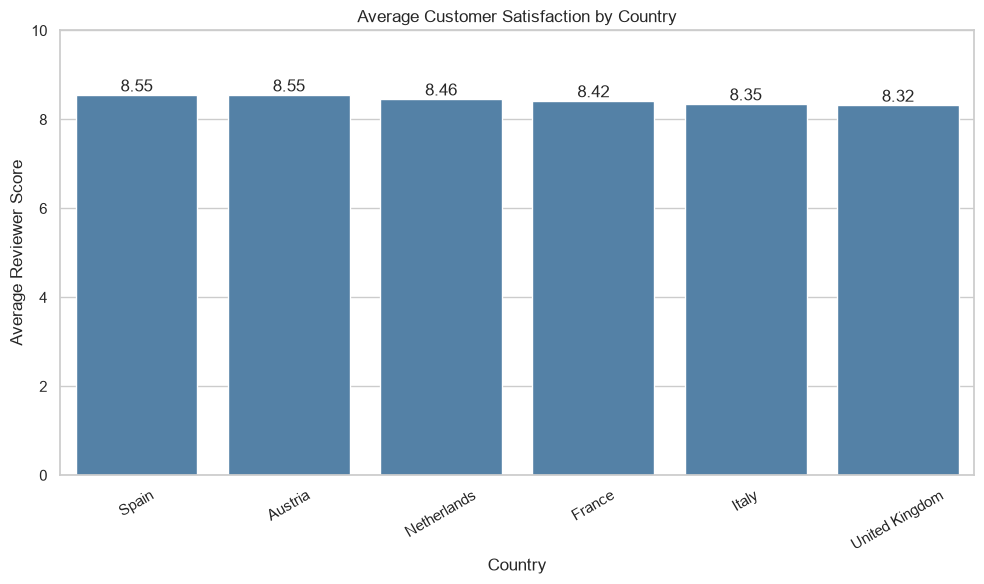

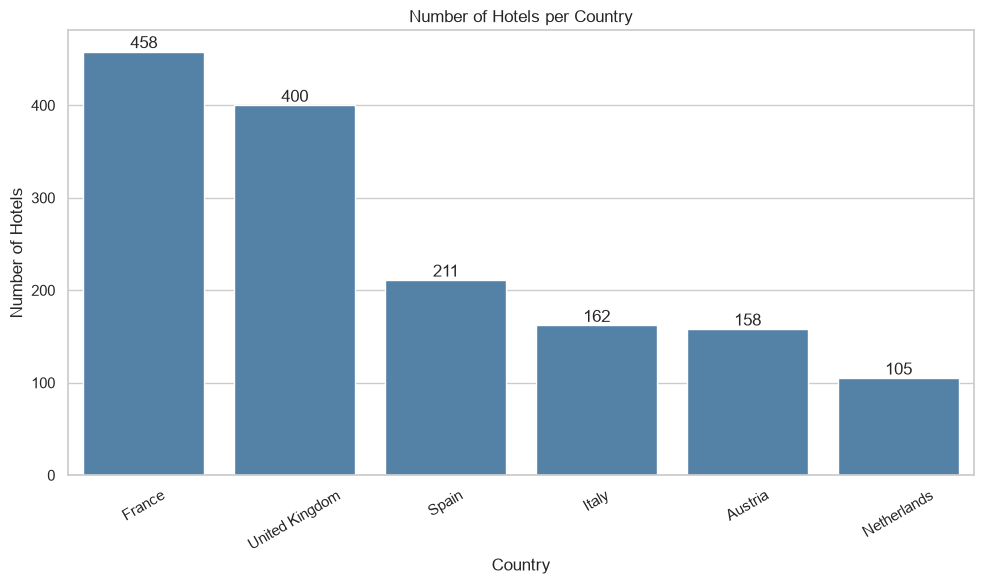

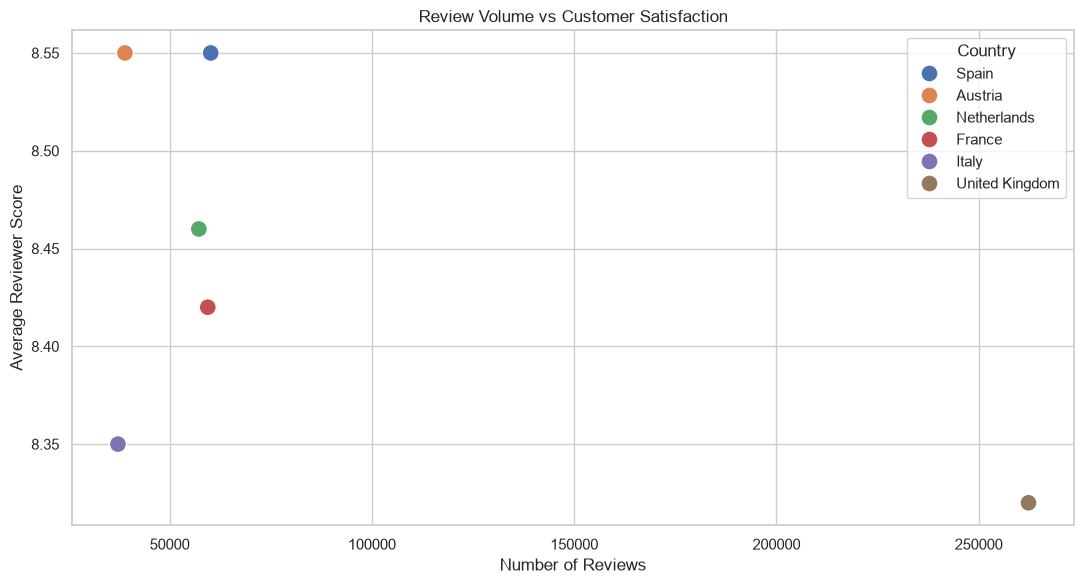


--- QUERY 1 VISUALIZATIONS ---
Three aggregation charts saved in results/


In [20]:
plot_country_summary(country_summary)

### 8.8 Interpretation of Query 1 Visualizations

#### Chart 1: Average Customer Satisfaction by Country

Spain and Austria have the highest average reviewer
scores after rounding, while the United Kingdom
has the lowest average score.

However, the differences between countries remain
relatively small, with a maximum displayed difference
of 0.23 points.

The results indicate generally high customer
satisfaction across all six countries.

#### Chart 2: Number of Hotels per Country

France has the largest number of distinct hotel
identifiers, followed by the United Kingdom.

The Netherlands has the smallest number of
represented hotel identifiers.

These results describe the geographical composition
of the dataset rather than the actual size of
each country's hospitality industry.

#### Chart 3: Review Volume versus Customer Satisfaction

The United Kingdom has substantially more reviews
than the other countries but has the lowest
average reviewer score.

This suggests that a higher number of reviews
does not necessarily correspond to higher
customer satisfaction.

However, the analysis contains only six country-level
observations and does not establish a causal or
statistically reliable relationship.

### 8.9 Business Implications

The results provide an initial overview of customer
satisfaction across the European hotels represented
in the dataset.

Hospitality businesses could use these indicators
as a starting point for geographical benchmarking.

Further analysis of positive and negative reviews
could help identify the specific factors associated
with customer satisfaction and dissatisfaction.S

## 9. Conclusion of the Individual Contribution

The exploratory data analysis, preprocessing and
country-level aggregation provide a reliable foundation
for the Hotel Reviews Analysis project.

### Main Findings

- The original dataset contains 515,738 reviews.
- After removing 526 duplicates, 515,212 reviews remain.
- The cleaned dataset contains 19 variables.
- Six European countries are represented.
- There are 1,494 distinct hotel identifiers.
- Customer satisfaction is generally high across
  all six countries.
- Spain and Austria have the highest displayed
  average reviewer scores.
- The United Kingdom has the largest review volume.
- France has the largest number of represented
  hotel identifiers.

### Contribution to the Collective Project

The cleaned dataset and analytical results provide
a common foundation for the remaining queries:

- Query 2: Frequent pattern mining and review analysis.
- Query 3: Temporal analysis and forecasting.
- Query 4: Spatial clustering.
- Interactive dashboard integration.

The modular implementation facilitates collaboration,
reproducibility, testing and integration of the
different analytical components.

## 10. Main Execution

The main function orchestrates the complete analytical
pipeline of this individual contribution.

It calls the previously defined functions in a
logical sequence, from data collection to analytical
visualization.

This approach ensures modularity, reproducibility
and maintainability.

The main function will subsequently be extended
to integrate the remaining analytical queries
and the interactive dashboard.

In [21]:
# Function: explore_data
# Input: DataFrame containing raw hotel reviews.
# Output: None. Displays dataset structure.

def explore_data(df):
    """
    Purpose:
        Explore the structure of the original dataset.

    Input:
        df: pandas DataFrame containing raw hotel reviews.

    Output:
        None. Displays dimensions, column names,
        data types and sample observations.
    """

    print("--- DATASET STRUCTURE ---")

    print("Number of rows:", df.shape[0])
    print("Number of columns:", df.shape[1])

    print("\n--- COLUMN NAMES ---")
    print(df.columns.tolist())

    print("\n--- DATA TYPES ---")
    display(df.dtypes.to_frame(name="Data Type"))

    print("\n--- FIRST FIVE OBSERVATIONS ---")
    display(df.head())

In [22]:
print(callable(explore_data))

True


HOTEL REVIEWS ANALYSIS IN EUROPE
--- DATASET STRUCTURE ---
Number of rows: 515738
Number of columns: 17

--- COLUMN NAMES ---
['Hotel_Address', 'Additional_Number_of_Scoring', 'Review_Date', 'Average_Score', 'Hotel_Name', 'Reviewer_Nationality', 'Negative_Review', 'Review_Total_Negative_Word_Counts', 'Total_Number_of_Reviews', 'Positive_Review', 'Review_Total_Positive_Word_Counts', 'Total_Number_of_Reviews_Reviewer_Has_Given', 'Reviewer_Score', 'Tags', 'days_since_review', 'lat', 'lng']

--- DATA TYPES ---


,Data Type
Hotel_Address,str
Additional_Number_of_Scoring,int64
Review_Date,str
Average_Score,float64
Hotel_Name,str
Reviewer_Nationality,str
Negative_Review,str
Review_Total_Negative_Word_Counts,int64
Total_Number_of_Reviews,int64
Positive_Review,str



--- FIRST FIVE OBSERVATIONS ---


,Hotel_Address,Additional_Number_of_Scoring,Review_Date,Average_Score,Hotel_Name,Reviewer_Nationality,Negative_Review,Review_Total_Negative_Word_Counts,Total_Number_of_Reviews,Positive_Review,Review_Total_Positive_Word_Counts,Total_Number_of_Reviews_Reviewer_Has_Given,Reviewer_Score,Tags,days_since_review,lat,lng
0,s Gravesandestraat 55 Oost 1092 AA Amsterdam ...,194,8/3/2017,7.7,Hotel Arena,Russia,I am so angry that i made this post available...,397,1403,Only the park outside of the hotel was beauti...,11,7,2.9,"[' Leisure trip ', ' Couple ', ' Duplex Double...",0 days,52.360576,4.915968
1,s Gravesandestraat 55 Oost 1092 AA Amsterdam ...,194,8/3/2017,7.7,Hotel Arena,Ireland,No Negative,0,1403,No real complaints the hotel was great great ...,105,7,7.5,"[' Leisure trip ', ' Couple ', ' Duplex Double...",0 days,52.360576,4.915968
2,s Gravesandestraat 55 Oost 1092 AA Amsterdam ...,194,7/31/2017,7.7,Hotel Arena,Australia,Rooms are nice but for elderly a bit difficul...,42,1403,Location was good and staff were ok It is cut...,21,9,7.1,"[' Leisure trip ', ' Family with young childre...",3 days,52.360576,4.915968
3,s Gravesandestraat 55 Oost 1092 AA Amsterdam ...,194,7/31/2017,7.7,Hotel Arena,United Kingdom,My room was dirty and I was afraid to walk ba...,210,1403,Great location in nice surroundings the bar a...,26,1,3.8,"[' Leisure trip ', ' Solo traveler ', ' Duplex...",3 days,52.360576,4.915968
4,s Gravesandestraat 55 Oost 1092 AA Amsterdam ...,194,7/24/2017,7.7,Hotel Arena,New Zealand,You When I booked with your company on line y...,140,1403,Amazing location and building Romantic setting,8,3,6.7,"[' Leisure trip ', ' Couple ', ' Suite ', ' St...",10 days,52.360576,4.915968


--- MISSING VALUES ---


,Missing Values,Missing Percentage (%)
Hotel_Address,0,0.00
Additional_Number_of_Scoring,0,0.00
Review_Date,0,0.00
Average_Score,0,0.00
Hotel_Name,0,0.00
Reviewer_Nationality,0,0.00
Negative_Review,0,0.00
Review_Total_Negative_Word_Counts,0,0.00
Total_Number_of_Reviews,0,0.00
Positive_Review,0,0.00



--- DUPLICATE ROWS ---
Number of duplicates: 526

--- NUMERICAL DESCRIPTIVE STATISTICS ---


,count,mean,std,min,25%,50%,75%,max
Additional_Number_of_Scoring,515738.0,498.08,500.54,1.00,169.00,341.00,660.00,2682.00
Average_Score,515738.0,8.40,0.55,5.20,8.10,8.40,8.80,9.80
Review_Total_Negative_Word_Counts,515738.0,18.54,29.69,0.00,2.00,9.00,23.00,408.00
Total_Number_of_Reviews,515738.0,2743.74,2317.46,43.00,1161.00,2134.00,3613.00,16670.00
Review_Total_Positive_Word_Counts,515738.0,17.78,21.80,0.00,5.00,11.00,22.00,395.00
Total_Number_of_Reviews_Reviewer_Has_Given,515738.0,7.17,11.04,1.00,1.00,3.00,8.00,355.00
Reviewer_Score,515738.0,8.40,1.64,2.50,7.50,8.80,9.60,10.00
lat,512470.0,49.44,3.47,41.33,48.21,51.50,51.52,52.40
lng,512470.0,2.82,4.58,-0.37,-0.14,0.01,4.83,16.43


--- TEMPORAL COVERAGE ---
First review date: 2015-08-04 00:00:00
Last review date: 2017-08-03 00:00:00
Invalid dates: 0
Number of months: 25

--- HOTEL INFORMATION ---
Distinct hotel names: 1492

--- GEOGRAPHICAL COVERAGE ---
Number of countries: 6

Number of reviews per country:


,Number of Reviews
Hotel_Address,
United Kingdom,262301
Spain,60149
France,59928
Netherlands,57214
Austria,38939
Italy,37207



Unidentified countries: 0


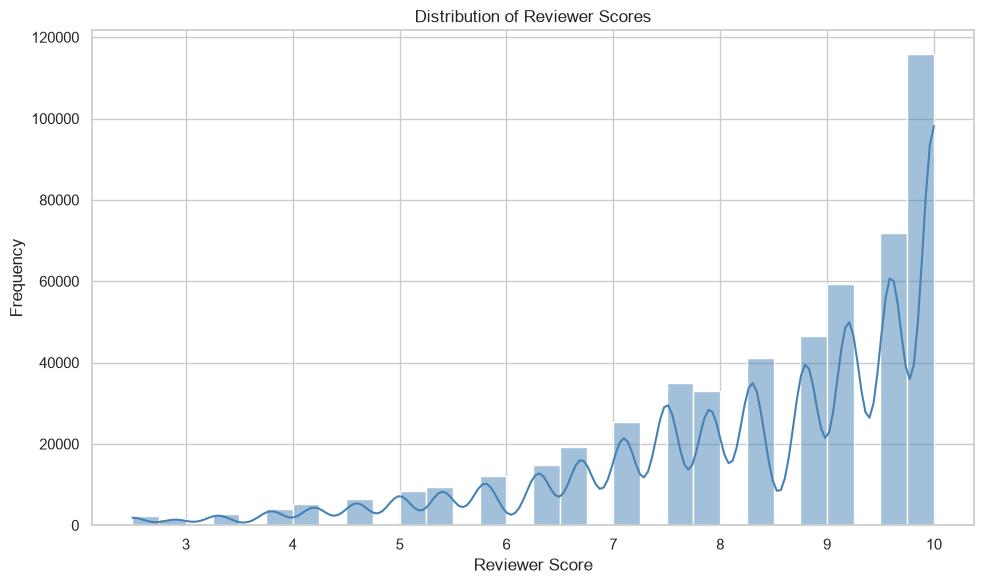

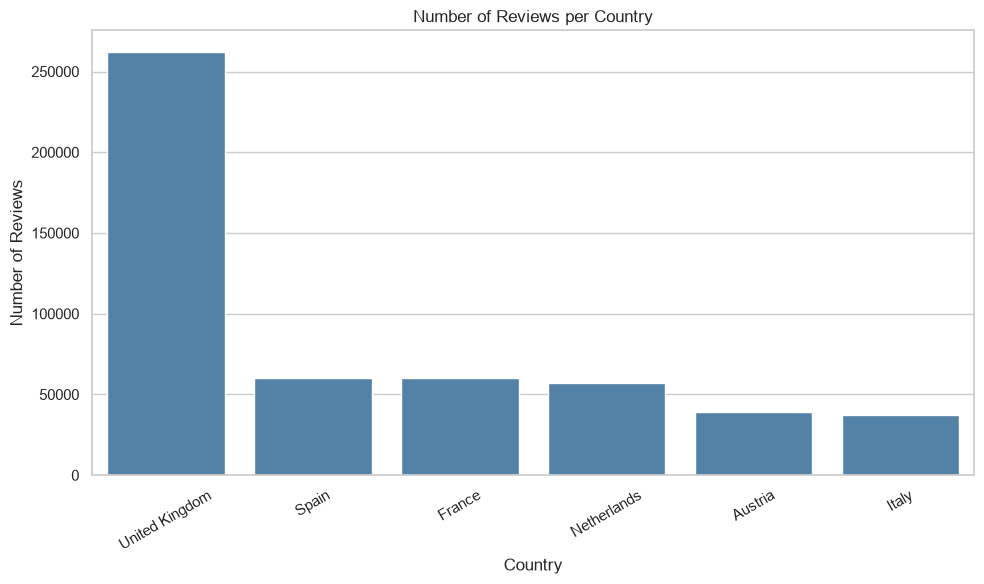

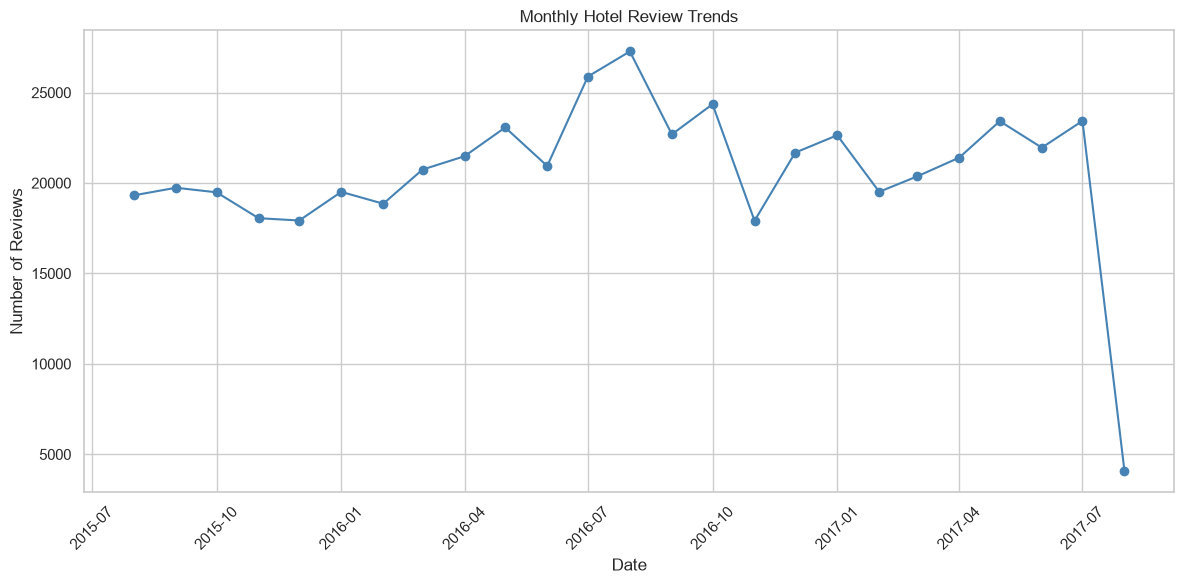


--- EDA VISUALIZATIONS ---
Three visualizations saved in results/
--- DATA PREPROCESSING ---
Initial rows: 515738
Removed duplicates: 526
Remaining rows: 515212
Number of columns: 19
Invalid dates: 0
Missing countries: 0
Distinct hotel identifiers: 1494
Missing latitude: 3268
Missing longitude: 3268

--- CLEANED DATASET SAVED ---
Location: c:\Users\USER\Documents\hotel-reviews-analysis-Programming\data\processed\hotel_reviews_cleaned.csv
--- QUERY 1: COUNTRY AGGREGATION ---


,Country,Number_of_Reviews,Number_of_Hotels,Average_Reviewer_Score,Median_Reviewer_Score
0,Spain,60149,211,8.55,9.2
1,Austria,38937,158,8.55,8.8
2,Netherlands,57211,105,8.46,8.8
3,France,59413,458,8.42,8.8
4,Italy,37204,162,8.35,8.8
5,United Kingdom,262298,400,8.32,8.8



--- QUERY 1 RESULTS SAVED ---
Location: c:\Users\USER\Documents\hotel-reviews-analysis-Programming\results\country_summary.csv


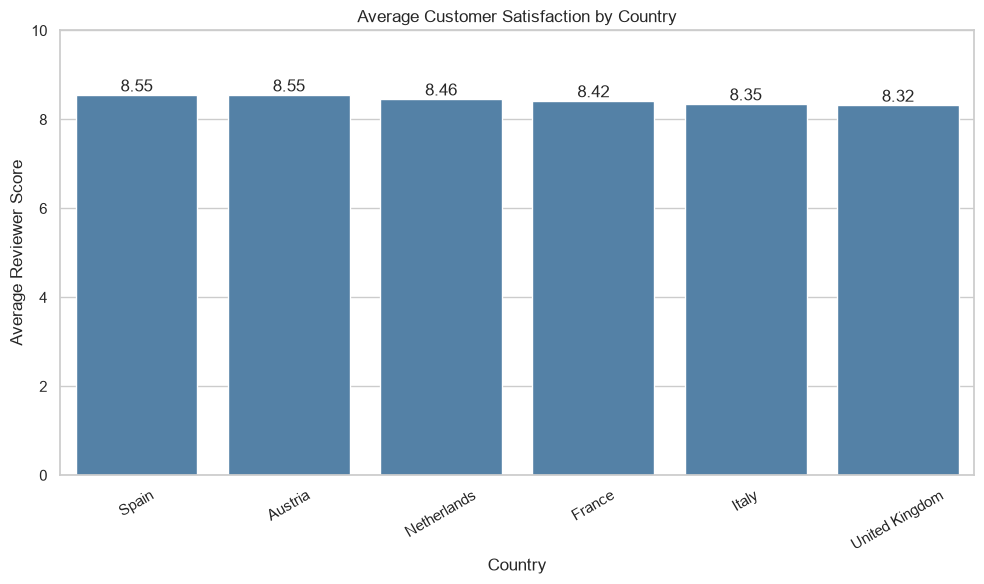

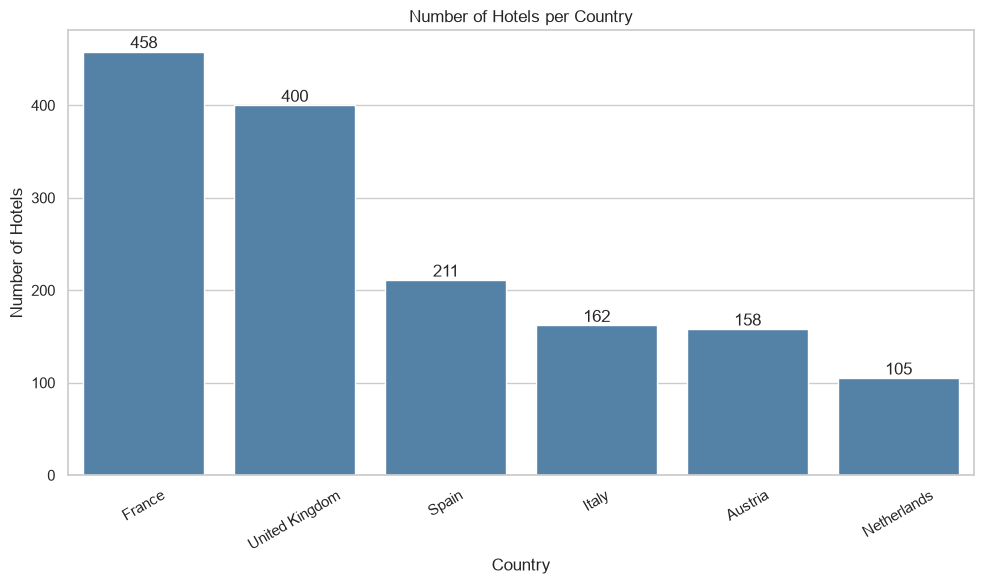

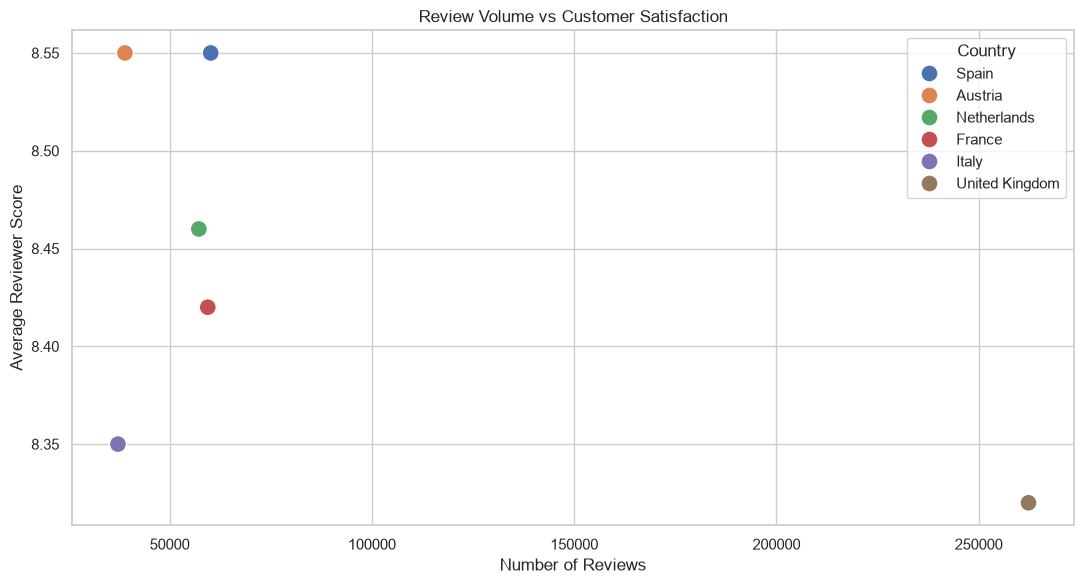


--- QUERY 1 VISUALIZATIONS ---
Three aggregation charts saved in results/

ANALYTICAL PIPELINE COMPLETED SUCCESSFULLY


In [23]:
# Function: main
# Input: None.
# Output: None. Executes the analytical pipeline.

def main():
    """
    Purpose:
        Execute the complete EDA, preprocessing
        and Query 1 analytical pipeline.

    Input:
        None.

    Output:
        None. Displays and saves analytical results.
    """

    print("=" * 60)
    print("HOTEL REVIEWS ANALYSIS IN EUROPE")
    print("=" * 60)

    # Step 1: Data collection
    df = load_data()

    # Step 2: Exploratory data analysis
    explore_data(df)
    analyze_data_quality(df)
    explore_temporal_spatial(df)
    plot_eda(df)

    # Step 3: Data preprocessing
    cleaned_df = clean_data(df)
    save_cleaned_data(cleaned_df)

    # Step 4: Query 1
    country_summary = aggregate_by_country(cleaned_df)
    save_aggregation_results(country_summary)

    # Step 5: Query 1 visualizations
    plot_country_summary(country_summary)

    print("\n" + "=" * 60)
    print("ANALYTICAL PIPELINE COMPLETED SUCCESSFULLY")
    print("=" * 60)


if __name__ == "__main__":
    main()